# Saldo de la Seguridad Social sin las transferencias del Estado

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "saldo-seguridad-social-sin-transferencias"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Saldo de la Seguridad Social sin las transferencias del Estado"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB (negativo: déficit; positivo: superávit)"  # capacidad (+) o necesidad (−) de financiación
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 0  # línea horizontal en el 0: separa el déficit (debajo) del superávit (encima)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El saldo de los *fondos de la Seguridad Social* (subsector S.1314 de la contabilidad nacional) sin contar las transferencias que reciben del resto de las administraciones públicas (Estado, comunidades autónomas y entidades locales), en porcentaje del PIB. Es el saldo de `saldo-seguridad-social` (capacidad o necesidad de financiación, B.9) menos esas transferencias, corrientes (D.7) y de capital (D.9).

**Cómo se lee.** Un valor de −3 significa que, sin las transferencias de las demás administraciones, los fondos de la Seguridad Social habrían gastado más de lo que ingresaron por un importe equivalente al 3 % del PIB. Aproxima lo que falta para pagar sus gastos con sus propios ingresos, sobre todo cotizaciones. La línea en el 0 separa el déficit del superávit.

**Limitaciones.**
- **Es una cuenta contable, no un juicio sobre a quién corresponde cada gasto.** Una parte de lo que pagan esas transferencias son prestaciones que la ley asigna al Estado (pensiones no contributivas, complementos a mínimos y, desde 2022, los gastos de la Ley 21/2021); el saldo sin transferencias las cuenta como gasto de la Seguridad Social sin financiación propia.
- **No es solo el sistema de pensiones.** En España el subsector incluye también el Servicio Público de Empleo Estatal (prestaciones por desempleo) y el Fondo de Garantía Salarial, cuyos gastos también financia en parte el Estado, y no incluye las pensiones de clases pasivas de los funcionarios.
- **Ruptura en 2002 en España.** Hasta 2001 el subsector incluía la asistencia sanitaria del antiguo Insalud, que pagaba el Estado con transferencias; en 2002 pasó a las comunidades autónomas y esas transferencias desaparecieron del subsector.
- **Cada país organiza el subsector a su manera.** En Estados Unidos no existe (la Social Security federal va dentro de la administración central). En Canadá recoge sobre todo los planes de pensiones públicos de Canadá y de Quebec, que no reciben transferencias de las demás administraciones. La OCDE no publica una media de este subsector.
- Eurostat da el subsector español desde 1995, primer año de la contabilidad nacional vigente (SEC 2010).

## 2. Descarga

- **España y UE-27:** Eurostat, cuentas no financieras anuales de las administraciones públicas (`gov_10a_main`), en millones de euros (`MIO_EUR`): saldo (`B9`) del subsector `S1314` y, en los subsectores Estado (`S1311`), comunidades autónomas (`S1312`) y entidades locales (`S1313`), las transferencias corrientes (`D7PAY_S1314`) y de capital (`D9PAY_S1314`) pagadas a los fondos de la Seguridad Social. PIB a precios corrientes de `nama_10_gdp` (`B1GQ`, `CP_MEUR`). Se trabaja en millones de euros y no en % del PIB, que Eurostat redondea a un decimal, para no sumar errores de redondeo.
- **Canadá:** OCDE, cuentas de las administraciones públicas (tabla 12, `OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12`): saldo (`B9`) del subsector `S1314` y las mismas transferencias pagadas por `S1311`, `S1312` y `S1313` (sector de contrapartida `S1314`), en moneda nacional, entre el PIB a precios corrientes (tabla 1, `B1GQ`).
- **Estados Unidos:** la misma tabla 12 de la OCDE, para comprobar que no publica el subsector `S1314`.

Solo para las comprobaciones: el saldo de España en % del PIB que publica Eurostat (`PC_GDP`) y las transferencias del Estado según la tabla 12 de la OCDE.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
PAGADORES = ("S1311", "S1312", "S1313")  # Estado, comunidades autónomas y entidades locales
TRANSFERENCIAS = ("D7PAY_S1314", "D9PAY_S1314")  # corrientes y de capital pagadas a la Seguridad Social

# Eurostat, millones de euros: saldo del subsector y transferencias que recibe del resto de las administraciones
BASE = {"freq": "A", "unit": "MIO_EUR"}
b9, fuentes_eu = eurostat.get("gov_10a_main", {**BASE, "sector": "S1314", "na_item": "B9"}, desde=DESDE)
transf = {}
for sector in PAGADORES:
    for item in TRANSFERENCIAS:
        d, _ = eurostat.get("gov_10a_main", {**BASE, "sector": sector, "na_item": item}, desde=DESDE)
        transf[(sector, item)] = d
pib_eu, _ = eurostat.get("nama_10_gdp", {"freq": "A", "unit": "CP_MEUR", "na_item": "B1GQ"}, desde=DESDE)
# Comprobación: el saldo en % del PIB que publica Eurostat
b9_pc, _ = eurostat.get("gov_10a_main", {"freq": "A", "unit": "PC_GDP", "sector": "S1314", "na_item": "B9"}, desde=DESDE)

# OCDE, tabla 12, moneda nacional. Dimensiones: FREQ.REF_AREA.SECTOR.COUNTERPART_SECTOR.ACCOUNTING_ENTRY.
# TRANSACTION.INSTR_ASSET.EXPENDITURE.UNIT_MEASURE.VALUATION.PRICE_BASE.TRANSFORMATION.TABLE_IDENTIFIER
DATAFLOW_T12 = "OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12,1.1"
AREAS_T12 = {"CAN": "canada", "ESP": "espana_ocde", "USA": "eeuu"}
t12, _ = oecd.get(DATAFLOW_T12, "A.{AREA}.S1314._Z.B.B9._Z._Z.XDC.S.V.N.T0200", areas=AREAS_T12, desde=DESDE)
t12_transf = {}
for sector in PAGADORES:
    for tr in ("D7", "D9"):
        d, _ = oecd.get(DATAFLOW_T12, f"A.{{AREA}}.{sector}.S1314.D.{tr}._Z._Z.XDC.S.V.N.T0200",
                        areas={"CAN": "canada", "ESP": "espana_ocde"}, desde=DESDE)
        t12_transf[(sector, tr)] = d
DATAFLOW_PIB = "OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_EXPENDITURE,2.0"
pib, _ = oecd.get(DATAFLOW_PIB, "A.{AREA}.S1.S1.B1GQ._Z._Z._Z.XDC.V.N.T0102", areas=AREAS_T12, desde=DESDE)
print("Áreas con el subsector S1314 en la tabla 12 de la OCDE:", sorted(t12["serie"].unique()))

Áreas con el subsector S1314 en la tabla 12 de la OCDE: ['canada', 'espana_ocde']


## 3. Transformación

- **España y UE-27:** saldo (B9) menos la suma de las transferencias corrientes y de capital pagadas a la Seguridad Social por el Estado, las comunidades autónomas y las entidades locales, todo en millones de euros, entre el PIB a precios corrientes, por 100. Solo los años con todas las partidas.
- **Canadá:** el mismo cálculo con la tabla 12 de la OCDE, en moneda nacional.
- **Estados Unidos y OCDE:** `null` (el subsector no existe en las cuentas de Estados Unidos y la OCDE no publica su media).

In [ ]:
def suma_transferencias(partes: dict, s: str) -> pd.Series:
    """Suma, año a año, las transferencias a la Seguridad Social de la serie `s`; solo años con todas las partidas."""
    return pd.concat([serie(d, s) for d in partes.values()], axis=1).dropna().sum(axis=1)


calc = {}
for s in ("espana", "ue27"):
    tr = suma_transferencias(transf, s)
    calc[s] = ((serie(b9, s) - tr) / serie(pib_eu, s) * 100).dropna()
tr_can = suma_transferencias(t12_transf, "canada")
calc["canada"] = ((serie(t12, "canada") - tr_can) / serie(pib, "canada") * 100).dropna()
assert "eeuu" not in set(t12["serie"]), "la OCDE publica ahora el subsector S1314 de EE. UU.: revisar la nota"

df = pd.concat(
    [pd.DataFrame({"serie": s, "periodo": v.index, "valor": v.values}) for s, v in calc.items()], ignore_index=True
)
assert df["valor"].between(-15, 15).all(), "saldo fuera de rango: ¿unidades?"


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


HOY = fuentes_eu[0].fecha_consulta
COD_EU = ("gov_10a_main (MIO_EUR): S1314 B9 menos D7PAY_S1314 y D9PAY_S1314 de S1311, S1312 y S1313; "
          "entre nama_10_gdp (B1GQ, CP_MEUR)")
fuentes = [FuenteMeta(f.serie, f.organismo, COD_EU, f.url, f.fecha_consulta) for f in fuentes_eu]
fuentes.append(
    FuenteMeta(
        "canada", oecd.ORGANISMO,
        "DSD_NASEC10@DF_TABLE12 (XDC): S1314 B9 menos D7 y D9 pagadas a S1314 por S1311, S1312 y S1313; "
        "entre DSD_NAMAIN10@DF_TABLE1_EXPENDITURE (B1GQ, XDC)",
        oecd.URL_EXPLORER, HOY,
    )
)
T12 = (oecd.ORGANISMO, "DSD_NASEC10@DF_TABLE12 (S1314, B9): sin el subsector fondos de la Seguridad Social", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(df, fuentes, {
    "ocde": (oecd.ORGANISMO, "DSD_NASEC10@DF_TABLE12 (S1314, B9): sin media de la OCDE", oecd.URL_EXPLORER),
    "eeuu": T12,
})
df.pivot(index="periodo", columns="serie", values="valor").round(2).tail(12)

serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2014,0.57,NaN,-3.69,NaN,-3.67
2015,0.60,NaN,-3.34,NaN,-3.36
2016,0.54,NaN,-3.08,NaN,-3.26
2017,0.57,NaN,-2.71,NaN,-3.12
2018,0.58,NaN,-2.64,NaN,-2.88
2019,0.67,NaN,-2.51,NaN,-2.94
2020,0.45,NaN,-5.73,NaN,-5.09
2021,0.82,NaN,-4.24,NaN,-4.24
2022,0.90,NaN,-3.17,NaN,-3.47


### Comprobaciones

1. España y UE-27: el saldo con transferencias calculado en millones de euros entre el PIB frente al que publica Eurostat en % del PIB (deben coincidir salvo el redondeo a un decimal).
2. España: las transferencias del Estado según Eurostat frente a las de la tabla 12 de la OCDE (deben coincidir: las dos salen de la notificación de España).
3. Canadá: cuánto suman las transferencias de las demás administraciones a su subsector.
4. España: peso del Estado entre los pagadores y de las transferencias de capital.

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


comp_b9 = {}
for s in ("espana", "ue27"):
    propio = serie(b9, s) / serie(pib_eu, s) * 100
    comp_b9[s] = (propio - serie(b9_pc, s)).dropna().abs().max()
print("Diferencia máxima con el saldo en % del PIB de Eurostat:", {k: round(v, 3) for k, v in comp_b9.items()})
assert max(comp_b9.values()) < 0.06, "el saldo calculado no coincide con el de Eurostat"

tr_es_eu = suma_transferencias(transf, "espana")
tr_es_ocde = suma_transferencias(t12_transf, "espana_ocde")
dif_ocde = ((tr_es_eu - tr_es_ocde).dropna().abs() / tr_es_eu * 100)
DESDE_IGUAL = int(dif_ocde[dif_ocde[::-1].cumsum()[::-1] < 0.01].index.min())  # desde aquí coinciden todos los años
DIF_OCDE = float(dif_ocde.max())
print(f"España: coinciden desde {DESDE_IGUAL}; diferencia máxima antes: {DIF_OCDE:.2f} % del importe")
assert DIF_OCDE < 5, "las transferencias de Eurostat y de la OCDE no coinciden"

TR_CAN_MAX = float(tr_can.abs().max())
print("Canadá: máximo de las transferencias de las demás administraciones (moneda nacional):", TR_CAN_MAX)

estado = (pd.concat([serie(transf[("S1311", i)], "espana") for i in TRANSFERENCIAS], axis=1).dropna().sum(axis=1)
          / tr_es_eu * 100).dropna()
EST_MIN = float(estado.min())
cap = (serie(transf[("S1311", "D9PAY_S1314")], "espana") / tr_es_eu * 100).dropna()
CAP_MAX = float(cap.max())
es = calc["espana"]
ULT = int(es.index.max())
CON_ULT = float(serie(b9_pc, "espana").loc[ULT])
SIN_ULT = float(es.loc[ULT])
print(f"España {ULT}: saldo {fmt(CON_ULT)} % con transferencias y {fmt(SIN_ULT)} % sin ellas; "
      f"Estado ≥ {EST_MIN:.1f} % de las transferencias; capital ≤ {CAP_MAX:.1f} %")

Diferencia máxima con el saldo en % del PIB de Eurostat: {'espana': np.float64(0.05), 'ue27': np.float64(0.048)}
España: coinciden desde 1999; diferencia máxima antes: 3.39 % del importe
Canadá: máximo de las transferencias de las demás administraciones (moneda nacional): 0.0
España 2025: saldo −0,3 % con transferencias y −3,2 % sin ellas; Estado ≥ 99.6 % de las transferencias; capital ≤ 2.0 %


### Notas

Una frase por decisión. Las cifras de las notas salen de las comprobaciones anteriores.

In [ ]:
NOTAS = [
    "España y UE-27: Eurostat, cuentas no financieras de las administraciones públicas (gov_10a_main), en millones "
    "de euros: saldo (B9) del subsector fondos de la Seguridad Social (S1314) menos las transferencias corrientes "
    "(D7PAY_S1314) y de capital (D9PAY_S1314) que le pagan el Estado (S1311), las comunidades autónomas (S1312) y las "
    "entidades locales (S1313), entre el PIB a precios corrientes (nama_10_gdp, B1GQ); contabilidad nacional SEC 2010 "
    "desde 1995. Media UE-27: agregado de composición actual (EU27_2020).",
    f"Es el saldo de la gráfica «Saldo de las cuentas de la Seguridad Social» sin las transferencias de las demás "
    f"administraciones: en España, en {ULT}, el {fmt(CON_ULT)} % del PIB con ellas y el {fmt(SIN_ULT)} % sin ellas. "
    f"En España casi todas vienen del Estado (al menos el {fmt(EST_MIN)} % cada año) y son corrientes (las de "
    f"capital no pasan del {fmt(CAP_MAX, 0)} %).",
    "Las transferencias pagan, entre otras cosas, prestaciones que la ley asigna al Estado (las pensiones no "
    "contributivas, los complementos a mínimos y, desde 2022, los gastos que la Ley 21/2021 asigna al Estado); el "
    "saldo sin transferencias las cuenta como gasto de la Seguridad Social sin ingresos propios que lo cubran.",
    "En España, el subsector incluye también el Servicio Público de Empleo Estatal (prestaciones por desempleo) y el "
    "Fondo de Garantía Salarial, y no incluye las pensiones de clases pasivas de los funcionarios, que paga el Estado.",
    "España, ruptura en 2002: hasta 2001 el subsector incluía la asistencia sanitaria del antiguo Insalud, financiada "
    "con transferencias del Estado, que en 2002 pasó a las comunidades autónomas.",
    "Canadá: OCDE, cuentas de las administraciones públicas (tabla 12, DSD_NASEC10@DF_TABLE12), saldo (B9) del "
    "subsector S1314 menos las transferencias corrientes y de capital que le pagan las demás administraciones, en "
    "moneda nacional, entre el PIB a precios corrientes (tabla 1, B1GQ). "
    + ("La OCDE no registra ninguna de esas transferencias, por lo que coincide con el saldo total."
       if TR_CAN_MAX == 0 else "Las transferencias son pequeñas: el saldo apenas cambia."),
    "EE. UU.: sin dato. Su contabilidad nacional no tiene el subsector fondos de la Seguridad Social: la Social "
    "Security federal se registra dentro de la administración central, y la OCDE no publica el subsector S1314.",
    "OCDE: sin dato. La OCDE no publica la media de este subsector.",
    f"España: las transferencias de Eurostat coinciden con las de la tabla 12 de la OCDE desde {DESDE_IGUAL}; antes "
    f"difieren como mucho en un {fmt(DIF_OCDE)} % del importe.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, cuentas no financieras de las administraciones públicas (gov_10a_main), en millones de euros: saldo (B9) del subsector fondos de la Seguridad Social (S1314) menos las transferencias corrientes (D7PAY_S1314) y de capital (D9PAY_S1314) que le pagan el Estado (S1311), las comunidades autónomas (S1312) y las entidades locales (S1313), entre el PIB a precios corrientes (nama_10_gdp, B1GQ); contabilidad nacional SEC 2010 desde 1995. Media UE-27: agregado de composición actual (EU27_2020).
- Es el saldo de la gráfica «Saldo de las cuentas de la Seguridad Social» sin las transferencias de las demás administraciones: en España, en 2025, el −0,3 % del PIB con ellas y el −3,2 % sin ellas. En España casi todas vienen del Estado (al menos el 99,6 % cada año) y son corrientes (las de capital no pasan del 2 %).
- Las transferencias pagan, entre otras cosas, prestaciones que la ley asigna al Estado (las pensiones no contributivas, los complementos a mínimos y, desde 2022, l

## 4. Visualización

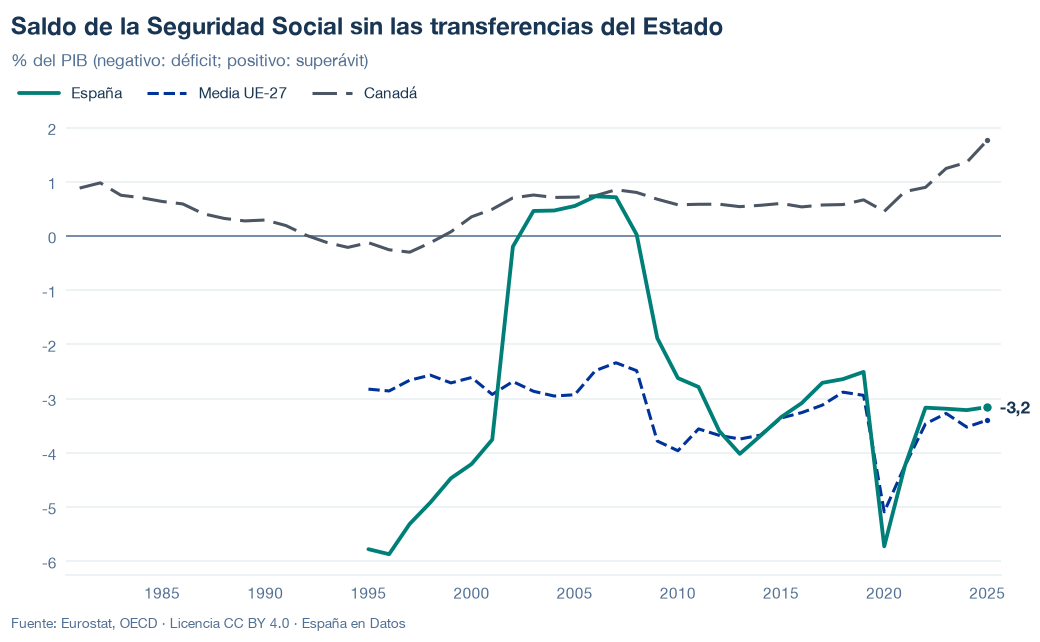

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/saldo-seguridad-social-sin-transferencias.json y data/saldo-seguridad-social-sin-transferencias.csv


## 6. Fuentes, notas y licencia

- Eurostat, `gov_10a_main` (`MIO_EUR`): `B9` de `S1314` y `D7PAY_S1314` y `D9PAY_S1314` de `S1311`, `S1312` y `S1313`, para España y la UE-27; `PC_GDP` del saldo para la comprobación. `nama_10_gdp` (`B1GQ`, `CP_MEUR`) para el PIB.
- OCDE, tabla 12 de las cuentas de las administraciones públicas (`OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12,1.1`) y tabla 1 de las cuentas nacionales (`OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_EXPENDITURE,2.0`) para Canadá y la comprobación de España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.